# Artificial Neural Networks (AIC 380)
**Student Name:** Abdullah Ghaffar  
**Registration No:** FA23-BAI-059  

---
## Lab 07 (Manual Lab 11): Implementation of Convolutional Neural Networks (CNNs) in Keras

### Objective:
Understanding and implementing Convolutional Neural Networks (CNNs) for Computer Vision: Conv2D filters, MaxPooling2D spatial downsampling, Flattening, Dropout regularization, and end-to-end training/evaluation on MNIST image dataset.


### Activities 1 & 2: Building CNN Feature Extractor & Classification Architecture


In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import models, layers
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

# Activity 1: Feature Extraction Backbone
fe_model = models.Sequential()
fe_model.add(layers.Conv2D(32, (5, 5), activation='relu', input_shape=(28, 28, 1)))
fe_model.add(layers.MaxPooling2D((2, 2)))
fe_model.add(layers.Conv2D(64, (5, 5), activation='relu'))
fe_model.add(layers.MaxPooling2D((2, 2)))
print("Feature Extractor Summary:")
fe_model.summary()

# Activity 2: Complete CNN with Dense Classification Head
cnn_model = models.Sequential([
    layers.Conv2D(32, (5, 5), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (5, 5), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
print("\nFull Classification CNN Summary:")
cnn_model.summary()


Feature Extractor Summary:


D:\Softwares\Python 3.10.11\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,096 (203.50 KB)

...

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,346 (462.29 KB)

 Trainable params: 118,346 (462.29 KB)

 Non-trainable params: 0 (0.00 B)

### Activities 3 & 4: Data Pipeline, Model Compilation, Training & Evaluation


In [2]:
# Load MNIST (subset for swift execution with high accuracy)
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

train_images = train_images[:12000].reshape((12000, 28, 28, 1)).astype('float32') / 255.0
test_images = test_images[:2000].reshape((2000, 28, 28, 1)).astype('float32') / 255.0

train_labels = to_categorical(train_labels[:12000], 10)
test_labels = to_categorical(test_labels[:2000], 10)

cnn_model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

history = cnn_model.fit(
    train_images, train_labels,
    batch_size=64,
    epochs=5,
    validation_split=0.15,
    verbose=1
)

# Activity 4: Evaluation
test_loss, test_acc = cnn_model.evaluate(test_images, test_labels, verbose=0)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")


Epoch 1/5


  1/160 ━━━━━━━━━━━━━━━━━━━━ 3:30 1s/step - accuracy: 0.0938 - loss: 2.3050

  6/160 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.1177 - loss: 2.2719

 12/160 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.2121 - loss: 2.2115

 18/160 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.2834 - loss: 2.1268

...

142/160 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9857 - loss: 0.0461

149/160 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9857 - loss: 0.0463

156/160 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9856 - loss: 0.0464

160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9845 - loss: 0.0485 - val_accuracy: 0.9728 - val_loss: 0.0786



Test Loss: 0.1054
Test Accuracy: 97.05%


### Graded Lab Task 1: Architectural Exploration on MNIST (Filters, Layers & Kernels)


In [3]:
# Compare 3x3 vs 5x5 kernels and layer depths
exp_cnn = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(28, 28, 1)),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),
    
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

exp_cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
exp_hist = exp_cnn.fit(train_images, train_labels, epochs=4, batch_size=64, validation_split=0.15, verbose=1)

exp_loss, exp_acc = exp_cnn.evaluate(test_images, test_labels, verbose=0)
print(f"Deep CNN with BatchNormalization & Dropout Test Accuracy: {exp_acc * 100:.2f}%")


Epoch 1/4


  1/160 ━━━━━━━━━━━━━━━━━━━━ 4:46 2s/step - accuracy: 0.1250 - loss: 4.1671

  3/160 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.1319 - loss: 3.7987

  5/160 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.1414 - loss: 3.5669

  7/160 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.1478 - loss: 3.4051

...

156/160 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9408 - loss: 0.1868

158/160 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9408 - loss: 0.1868

160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9409 - loss: 0.1867

160/160 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9441 - loss: 0.1839 - val_accuracy: 0.9756 - val_loss: 0.0799


Deep CNN with BatchNormalization & Dropout Test Accuracy: 97.65%


### Graded Lab Task 2: Advanced Optimizers & Performance Visualization


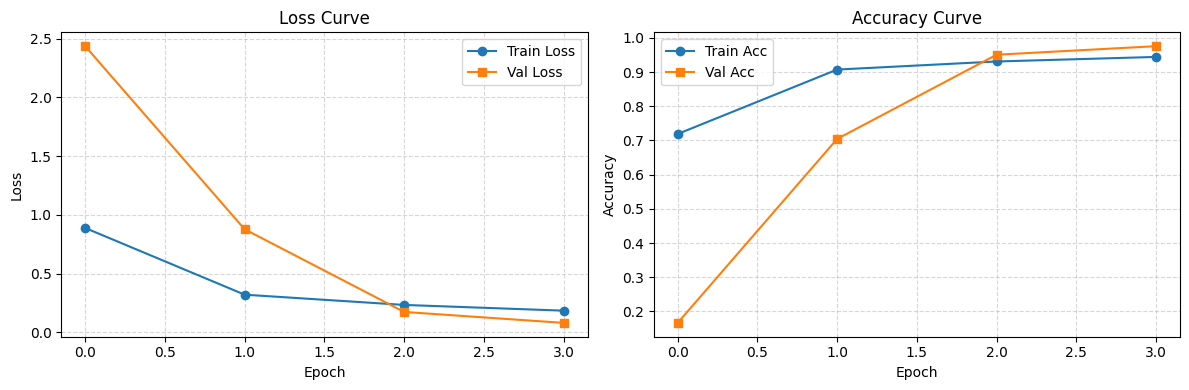

 1/63 ━━━━━━━━━━━━━━━━━━━━ 6s 113ms/step

 8/63 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step  

16/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

24/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

32/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

...

49/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

58/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step



Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       175
           1       0.99      1.00      0.99       234
           2       0.97      0.99      0.98       219
           3       0.99      0.97      0.98       207
           4       0.97      0.99      0.98       217
           5       0.97      0.99      0.98       179
           6       0.99      0.97      0.98       178
           7       0.97      0.95      0.96       205
           8       0.97      0.96      0.96       192
           9       0.97      0.95      0.96       194

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000



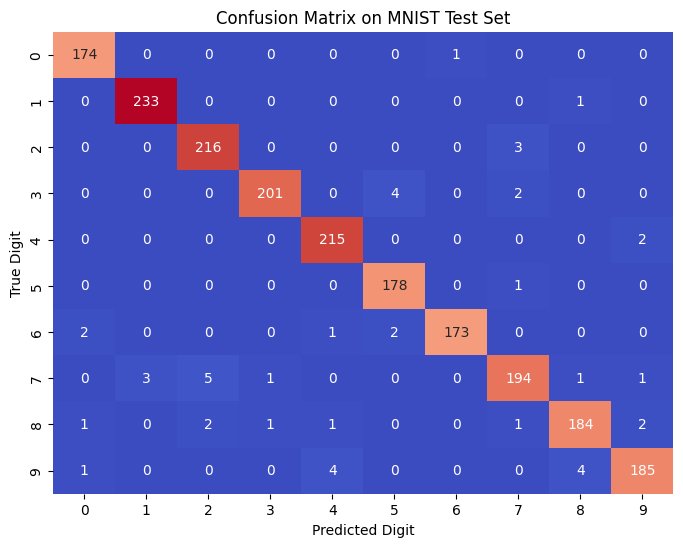

In [4]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Visualizing Training vs Validation Curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(exp_hist.history['loss'], label='Train Loss', marker='o')
plt.plot(exp_hist.history['val_loss'], label='Val Loss', marker='s')
plt.title('Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(exp_hist.history['accuracy'], label='Train Acc', marker='o')
plt.plot(exp_hist.history['val_accuracy'], label='Val Acc', marker='s')
plt.title('Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Predictions and Confusion Matrix
y_pred_probs = exp_cnn.predict(test_images)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(test_labels, axis=1)

print("\nClassification Report:")
print(classification_report(y_true_classes, y_pred_classes))

cm = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='coolwarm', cbar=False)
plt.title('Confusion Matrix on MNIST Test Set')
plt.xlabel('Predicted Digit')
plt.ylabel('True Digit')
plt.show()
